# Experiment 003: 3B three-seed analysis plots

Figures from all three completed 003 SFT-to-GRPO runs. The earlier 0.5B run
`002_COLAB_FULL_B05_sft_grpo_seed0` stays in the original RQ2 scale panels.
All tier values are rebuilt from the current subject mapping because seed 0 was
written before the easy and medium subject swap. Reads only saved json/jsonl,
no gpu needed. Figures land in `analysis/figures/003_1/` as 300dpi pngs.

In [1]:
# find the repo root and load the completed results once
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, mcnemar_exact, paired_delta_ci
from data.subjects import tier_of

RES = ROOT / "results"
SEEDS = (0, 1, 2)
R3 = {seed: RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}" for seed in SEEDS}
B3 = RES / "base_evals" / "003_COLAB_FULL_B3"
R2 = RES / "002_COLAB_FULL_B05_sft_grpo_seed0"
B2 = RES / "base_evals" / "002_COLAB_FULL_B05"
FIG = ROOT / "analysis" / "figures" / "003_1"
FIG.mkdir(parents=True, exist_ok=True)

TIERS = ["easy", "medium", "hard"]
COND = ["base", "sft", "grpo"]
COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    xs = [row["step"] for row in trainlog if key in row and "step" in row]
    ys = [row[key] for row in trainlog if key in row and "step" in row]
    return np.array(xs), np.array(ys, dtype=float)

def smooth(values, window=15):
    # use a rolling mean because the step values are noisy
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def retier(rows):
    # rebuild tiers from the current subject mapping for cross-era comparisons
    rebuilt = []
    for row in rows:
        row = dict(row)
        row["tier"] = tier_of(row["subject"])
        assert row["tier"] in TIERS
        rebuilt.append(row)
    return rebuilt

def rebuild_summary(saved, rows, generative):
    # keep saved metadata but recompute grouped values from the retiered rows
    out = dict(saved)
    out["per_tier_acc"] = {
        tier: float(np.mean([row["correct"] for row in rows if row["tier"] == tier]))
        for tier in TIERS
    }
    subjects = sorted({row["subject"] for row in rows})
    out["per_subject_acc"] = {
        subject: float(np.mean([row["correct"] for row in rows if row["subject"] == subject]))
        for subject in subjects
    }
    if generative:
        out["format_compliance"] = float(np.mean([row["format_ok"] for row in rows]))
        out["extraction_failure_rate"] = float(np.mean([row["pred"] is None for row in rows]))
        out["mean_len"] = float(np.mean([row["n_tokens"] for row in rows]))
    return out

def load_run(run_dir, base_dir):
    pred_paths = {
        "base": base_dir / "base_preds.jsonl",
        "sft": run_dir / "sft_preds.jsonl",
        "grpo": run_dir / "grpo_preds.jsonl",
    }
    lp_paths = {
        "base": base_dir / "base_logprob_preds.jsonl",
        "sft": run_dir / "sft_logprob_preds.jsonl",
        "grpo": run_dir / "grpo_logprob_preds.jsonl",
    }
    preds = {condition: retier(jsonl(path)) for condition, path in pred_paths.items()}
    lp_preds = {condition: retier(jsonl(path)) for condition, path in lp_paths.items()}
    eval_saved = {
        "base": jload(base_dir / "base_eval.json"),
        "sft": jload(run_dir / "sft_eval.json"),
        "grpo": jload(run_dir / "grpo_eval.json"),
    }
    lp_saved = {
        "base": jload(base_dir / "base_logprob.json"),
        "sft": jload(run_dir / "sft_logprob.json"),
        "grpo": jload(run_dir / "grpo_logprob.json"),
    }
    return {
        "g": jload(run_dir / "grpo_trainlog.json"),
        "s": jload(run_dir / "sft_trainlog.json"),
        "eval": {condition: rebuild_summary(eval_saved[condition], preds[condition], True) for condition in COND},
        "lp": {condition: rebuild_summary(lp_saved[condition], lp_preds[condition], False) for condition in COND},
        "preds": preds,
        "lp_preds": lp_preds,
        "man": jload(run_dir / "manifest.json"),
    }

D3S = {seed: load_run(R3[seed], B3) for seed in SEEDS}
D3 = D3S[0]
D2 = load_run(R2, B2)

for seed, data in D3S.items():
    reward_steps = [row["step"] for row in data["g"] if "reward" in row and "step" in row]
    assert reward_steps == list(range(1, 501))
    for condition in COND:
        assert len(data["preds"][condition]) == 1884
        assert len(data["lp_preds"][condition]) == 1884

print("loaded all three completed 003 seeds and the original 002 comparison")

loaded all three completed 003 seeds and the original 002 comparison


## 1. 3B GRPO training dynamics

saved fig01_grpo_reward_curves_3b


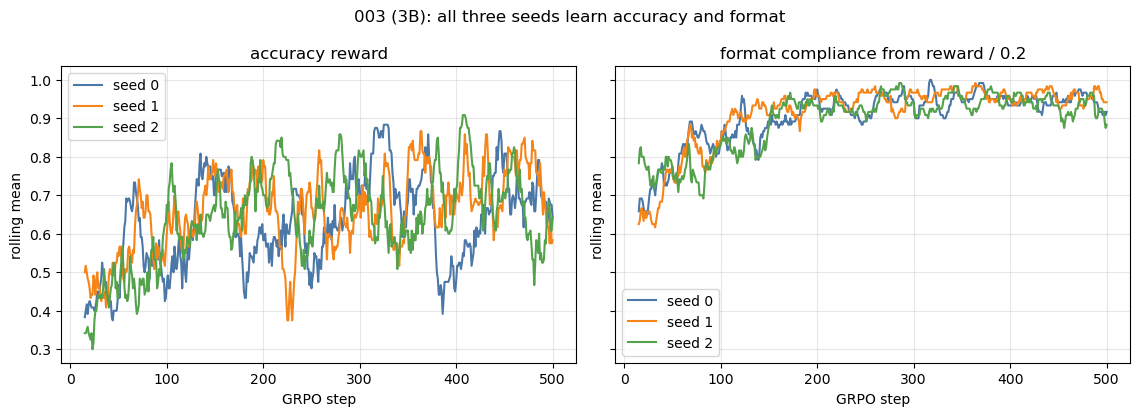

In [2]:
# compare the three GRPO reward traces on the same axes
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
window = 15
for seed, data in D3S.items():
    x, accuracy_reward = series(data["g"], "rewards/accuracy_reward/mean")
    _, format_reward = series(data["g"], "rewards/format_reward/mean")
    axes[0].plot(x[window - 1:], smooth(accuracy_reward, window), color=COLORS[seed], label=f"seed {seed}")
    axes[1].plot(x[window - 1:], smooth(format_reward, window) / 0.2, color=COLORS[seed], label=f"seed {seed}")
axes[0].set_title("accuracy reward")
axes[1].set_title("format compliance from reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylabel("rolling mean")
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("003 (3B): all three seeds learn accuracy and format")
fig.tight_layout()
save(fig, "fig01_grpo_reward_curves_3b")
plt.show()

saved fig02_kl_3b_vs_0p5b


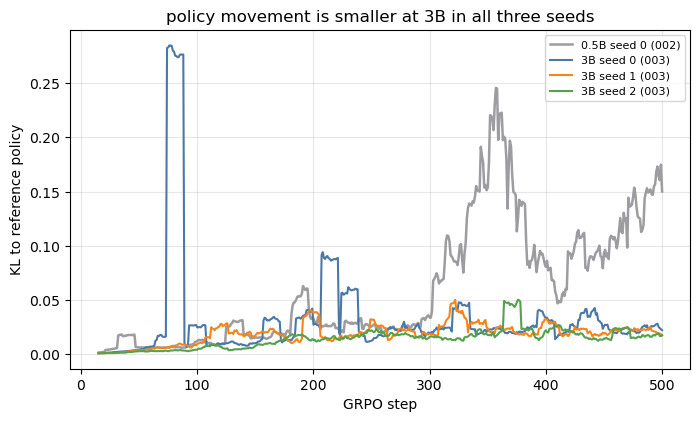

In [3]:
# keep all three 3B seeds visible in the policy-movement comparison
fig, ax = plt.subplots(figsize=(8, 4.4))
x, y = series(D2["g"], "kl")
ax.plot(x[14:], smooth(y), color="#9D9DA1", lw=1.8, label="0.5B seed 0 (002)")
for seed, data in D3S.items():
    x, y = series(data["g"], "kl")
    ax.plot(x[14:], smooth(y), color=COLORS[seed], label=f"3B seed {seed} (003)")
ax.set_xlabel("GRPO step")
ax.set_ylabel("KL to reference policy")
ax.set_title("policy movement is smaller at 3B in all three seeds")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
save(fig, "fig02_kl_3b_vs_0p5b")
plt.show()

saved fig03_clipped_length_3b


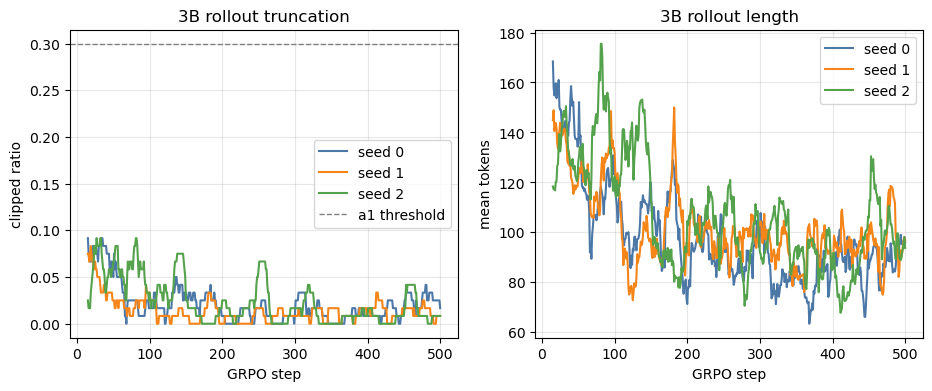

In [4]:
# compare rollout truncation and length for all three 3B seeds
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for seed, data in D3S.items():
    x, clipped = series(data["g"], "completions/clipped_ratio")
    axes[0].plot(x[14:], smooth(clipped), color=COLORS[seed], label=f"seed {seed}")
    x, mean_length = series(data["g"], "completions/mean_length")
    axes[1].plot(x[14:], smooth(mean_length), color=COLORS[seed], label=f"seed {seed}")
axes[0].axhline(0.3, ls="--", c="grey", lw=1, label="a1 threshold")
axes[0].set_title("3B rollout truncation")
axes[0].set_xlabel("GRPO step")
axes[0].set_ylabel("clipped ratio")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].set_title("3B rollout length")
axes[1].set_xlabel("GRPO step")
axes[1].set_ylabel("mean tokens")
axes[1].legend()
axes[1].grid(alpha=0.3)
save(fig, "fig03_clipped_length_3b")
plt.show()

## 2. 3B headline results

saved fig04_headline_ceiling_3b


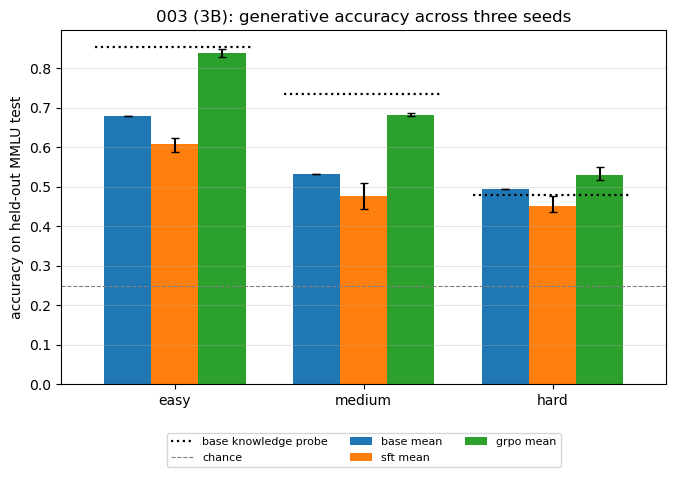

In [5]:
# use three-seed means and ranges for the 3B headline endpoints
fig, ax = plt.subplots(figsize=(7.8, 4.6))
xpos = np.arange(len(TIERS))
width = 0.25
for index, condition in enumerate(COND):
    seed_values = np.array([
        [data["eval"][condition]["per_tier_acc"][tier] for tier in TIERS]
        for data in D3S.values()
    ])
    values = seed_values.mean(axis=0)
    errors = np.vstack([
        np.maximum(values - seed_values.min(axis=0), 0),
        np.maximum(seed_values.max(axis=0) - values, 0),
    ])
    positions = xpos + (index - 1) * width
    ax.bar(positions, values, width, yerr=errors, capsize=3, label=f"{condition} mean")
for index, tier in enumerate(TIERS):
    ax.hlines(D3["lp"]["base"]["per_tier_acc"][tier], index - 0.42, index + 0.42, colors="black", ls=":", lw=1.6)
ax.hlines(0, 10, 11, colors="black", ls=":", lw=1.6, label="base knowledge probe")
ax.axhline(0.25, color="grey", lw=0.8, ls="--", label="chance")
ax.set_xlim(-0.6, 2.6)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("accuracy on held-out MMLU test")
ax.set_title("003 (3B): generative accuracy across three seeds")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(alpha=0.3, axis="y")
save(fig, "fig04_headline_ceiling_3b")
plt.show()

saved fig05_delta_ci_3b


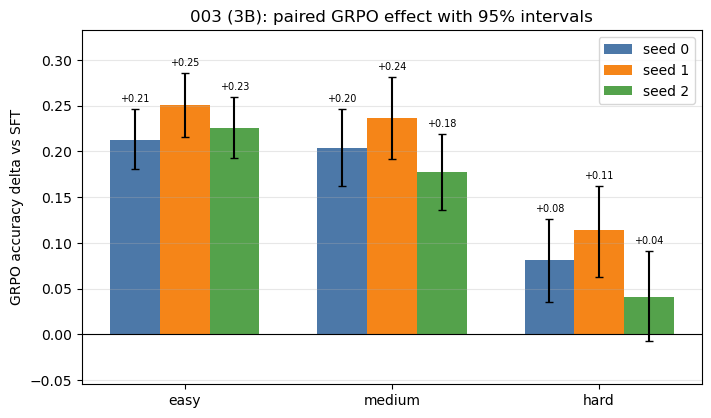

In [6]:
# compare the paired GRPO effect for all three 3B seeds
fig, ax = plt.subplots(figsize=(8, 4.6))
xpos = np.arange(len(TIERS))
width = 0.24
for index, (seed, data) in enumerate(D3S.items()):
    sft_rows, grpo_rows = align_pred_rows(data["preds"]["sft"], data["preds"]["grpo"])
    deltas, errors = [], [[], []]
    for tier in TIERS:
        paired = [(a["correct"], b["correct"]) for a, b in zip(sft_rows, grpo_rows) if a["tier"] == tier]
        sft = [a for a, _ in paired]
        grpo = [b for _, b in paired]
        delta, low, high = paired_delta_ci(sft, grpo, seed=300 + seed)
        deltas.append(delta)
        errors[0].append(delta - low)
        errors[1].append(high - delta)
    positions = xpos + (index - 1) * width
    bars = ax.bar(positions, deltas, width, yerr=errors, capsize=3, color=COLORS[seed], label=f"seed {seed}")
    ax.bar_label(bars, labels=[f"{delta:+.2f}" for delta in deltas], padding=4, fontsize=7)
ax.margins(y=0.16)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("GRPO accuracy delta vs SFT")
ax.set_title("003 (3B): paired GRPO effect with 95% intervals")
ax.legend()
ax.grid(alpha=0.3, axis="y")
save(fig, "fig05_delta_ci_3b")
plt.show()

## 3. Original RQ2 scale context (002 vs 003)

saved fig06_scale_grpo_vs_ceiling


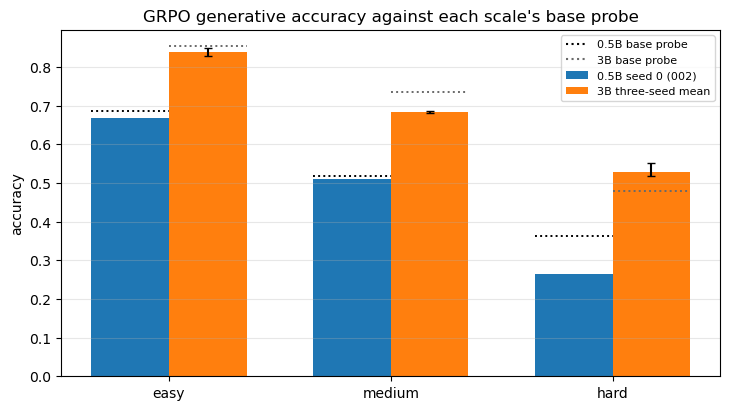

In [7]:
# compare the original 0.5B artifact with the three-seed 3B mean and range
fig, ax = plt.subplots(figsize=(8.5, 4.5))
xpos = np.arange(len(TIERS))
width = 0.35
gen_05 = np.array([D2["eval"]["grpo"]["per_tier_acc"][tier] for tier in TIERS])
gen_3 = np.array([
    [data["eval"]["grpo"]["per_tier_acc"][tier] for tier in TIERS]
    for data in D3S.values()
])
gen_3_mean = gen_3.mean(axis=0)
gen_3_error = np.vstack([
    np.maximum(gen_3_mean - gen_3.min(axis=0), 0),
    np.maximum(gen_3.max(axis=0) - gen_3_mean, 0),
])
ax.bar(xpos - width / 2, gen_05, width, label="0.5B seed 0 (002)")
ax.bar(xpos + width / 2, gen_3_mean, width, yerr=gen_3_error, capsize=3, label="3B three-seed mean")
for index, tier in enumerate(TIERS):
    ax.hlines(D2["lp"]["base"]["per_tier_acc"][tier], index - width, index, colors="black", ls=":", lw=1.4)
    ax.hlines(D3["lp"]["base"]["per_tier_acc"][tier], index, index + width, colors="dimgrey", ls=":", lw=1.4)
ax.plot([], [], color="black", ls=":", label="0.5B base probe")
ax.plot([], [], color="dimgrey", ls=":", label="3B base probe")
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("accuracy")
ax.set_title("GRPO generative accuracy against each scale's base probe")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
save(fig, "fig06_scale_grpo_vs_ceiling")
plt.show()

saved fig07_scale_delta


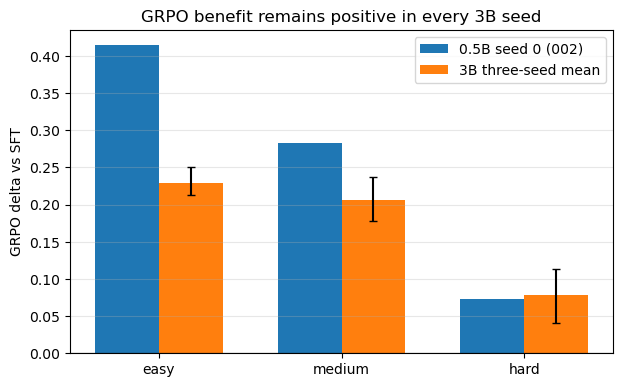

In [8]:
# keep the three-seed range visible in the original cross-scale GRPO gain
fig, ax = plt.subplots(figsize=(7, 4.2))
xpos = np.arange(len(TIERS))
width = 0.35
gain_05 = np.array([
    D2["eval"]["grpo"]["per_tier_acc"][tier] - D2["eval"]["sft"]["per_tier_acc"][tier]
    for tier in TIERS
])
gain_3 = np.array([
    [data["eval"]["grpo"]["per_tier_acc"][tier] - data["eval"]["sft"]["per_tier_acc"][tier] for tier in TIERS]
    for data in D3S.values()
])
gain_3_mean = gain_3.mean(axis=0)
gain_3_error = np.vstack([
    np.maximum(gain_3_mean - gain_3.min(axis=0), 0),
    np.maximum(gain_3.max(axis=0) - gain_3_mean, 0),
])
ax.bar(xpos - width / 2, gain_05, width, label="0.5B seed 0 (002)")
ax.bar(xpos + width / 2, gain_3_mean, width, yerr=gain_3_error, capsize=3, label="3B three-seed mean")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("GRPO delta vs SFT")
ax.set_title("GRPO benefit remains positive in every 3B seed")
ax.legend()
ax.grid(alpha=0.3, axis="y")
save(fig, "fig07_scale_delta")
plt.show()

saved fig08_gap_to_ceiling


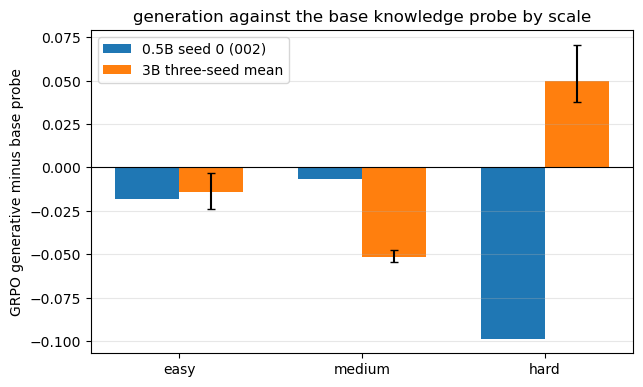

In [9]:
# compare GRPO generation with the shared base knowledge probe
fig, ax = plt.subplots(figsize=(7, 4.2))
xpos = np.arange(len(TIERS))
width = 0.35
gap_05 = np.array([
    D2["eval"]["grpo"]["per_tier_acc"][tier] - D2["lp"]["base"]["per_tier_acc"][tier]
    for tier in TIERS
])
gap_3 = np.array([
    [data["eval"]["grpo"]["per_tier_acc"][tier] - data["lp"]["base"]["per_tier_acc"][tier] for tier in TIERS]
    for data in D3S.values()
])
gap_3_mean = gap_3.mean(axis=0)
gap_3_error = np.vstack([
    np.maximum(gap_3_mean - gap_3.min(axis=0), 0),
    np.maximum(gap_3.max(axis=0) - gap_3_mean, 0),
])
ax.bar(xpos - width / 2, gap_05, width, label="0.5B seed 0 (002)")
ax.bar(xpos + width / 2, gap_3_mean, width, yerr=gap_3_error, capsize=3, label="3B three-seed mean")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("GRPO generative minus base probe")
ax.set_title("generation against the base knowledge probe by scale")
ax.legend()
ax.grid(alpha=0.3, axis="y")
save(fig, "fig08_gap_to_ceiling")
plt.show()

saved fig09_knowledge_by_stage


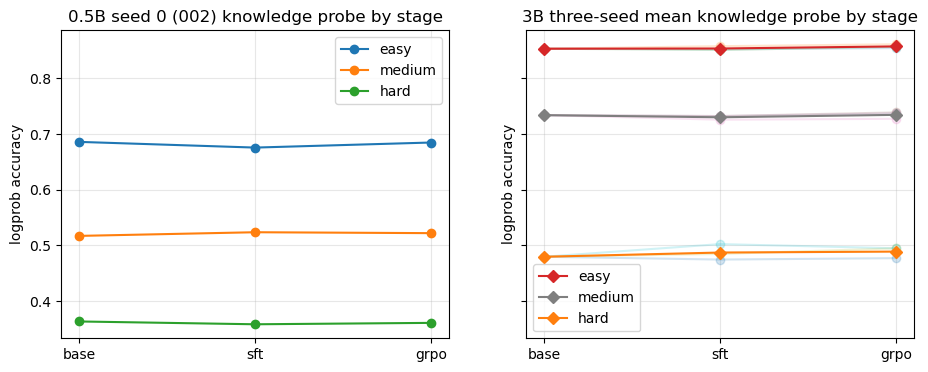

In [10]:
# compare the knowledge probe across stages and all three 3B seeds
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for tier in TIERS:
    values = [D2["lp"][condition]["per_tier_acc"][tier] for condition in COND]
    axes[0].plot(COND, values, "o-", label=tier)
    seed_values = np.array([
        [data["lp"][condition]["per_tier_acc"][tier] for condition in COND]
        for data in D3S.values()
    ])
    for values in seed_values:
        axes[1].plot(COND, values, "o-", alpha=0.2)
    axes[1].plot(COND, seed_values.mean(axis=0), "D-", label=tier)
for ax, label in zip(axes, ("0.5B seed 0 (002)", "3B three-seed mean")):
    ax.set_title(f"{label} knowledge probe by stage")
    ax.grid(alpha=0.3)
    ax.set_ylabel("logprob accuracy")
axes[0].legend()
axes[1].legend()
save(fig, "fig09_knowledge_by_stage")
plt.show()

## 4. What the 3B model writes

saved fig10_length_and_think_3b


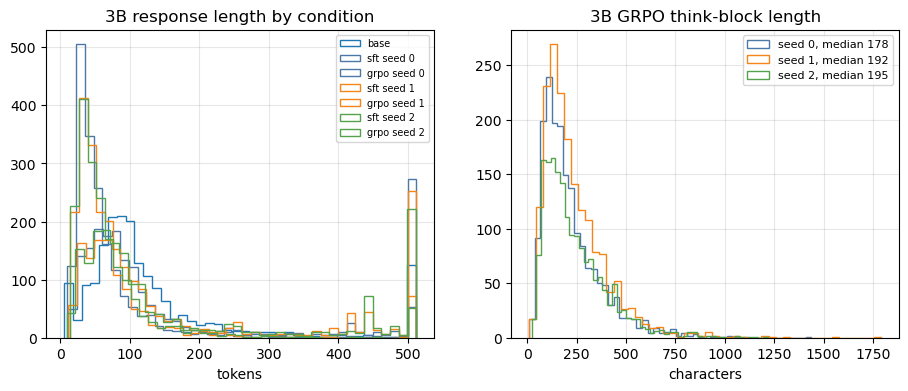

In [11]:
# compare response lengths and think-block lengths across all three seeds
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist([row["n_tokens"] for row in D3["preds"]["base"]], bins=40, histtype="step", lw=1.5, label="base")
for seed, data in D3S.items():
    for condition, linestyle in (("sft", "--"), ("grpo", "-")):
        axes[0].hist(
            [row["n_tokens"] for row in data["preds"][condition]], bins=40,
            histtype="step", lw=1.2, ls=linestyle, color=COLORS[seed], label=f"{condition} seed {seed}",
        )
    lengths = []
    for row in data["preds"]["grpo"]:
        match = re.search(r"(.*?)</think>", "<think>" + row["output"], re.DOTALL)
        if match:
            lengths.append(len(match.group(1).replace("<think>", "").strip()))
    axes[1].hist(lengths, bins=50, histtype="step", lw=1.3, color=COLORS[seed], label=f"seed {seed}, median {np.median(lengths):.0f}")
axes[0].set_title("3B response length by condition")
axes[0].set_xlabel("tokens")
axes[0].legend(fontsize=7)
axes[0].grid(alpha=0.3)
axes[1].set_title("3B GRPO think-block length")
axes[1].set_xlabel("characters")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
save(fig, "fig10_length_and_think_3b")
plt.show()

saved fig11_per_subject_delta_3b


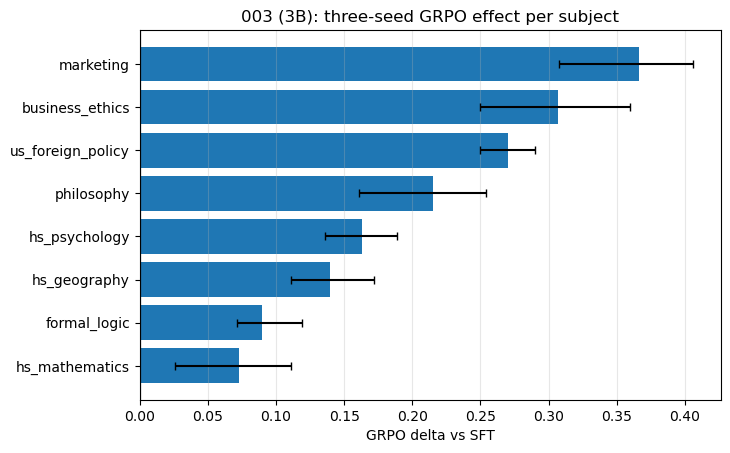

In [12]:
# sort subjects by the three-seed mean GRPO effect
subjects = list(D3["eval"]["sft"]["per_subject_acc"])
seed_deltas = np.array([
    [data["eval"]["grpo"]["per_subject_acc"][subject] - data["eval"]["sft"]["per_subject_acc"][subject] for subject in subjects]
    for data in D3S.values()
])
mean_deltas = seed_deltas.mean(axis=0)
order = np.argsort(mean_deltas)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ordered_mean = mean_deltas[order]
ordered_seeds = seed_deltas[:, order]
errors = np.vstack([
    np.maximum(ordered_mean - ordered_seeds.min(axis=0), 0),
    np.maximum(ordered_seeds.max(axis=0) - ordered_mean, 0),
])
ax.barh([subjects[index].replace("high_school_", "hs_") for index in order], ordered_mean, xerr=errors, capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("GRPO delta vs SFT")
ax.set_title("003 (3B): three-seed GRPO effect per subject")
ax.grid(alpha=0.3, axis="x")
save(fig, "fig11_per_subject_delta_3b")
plt.show()

## 5. Compute

saved fig12_stage_cost_3b


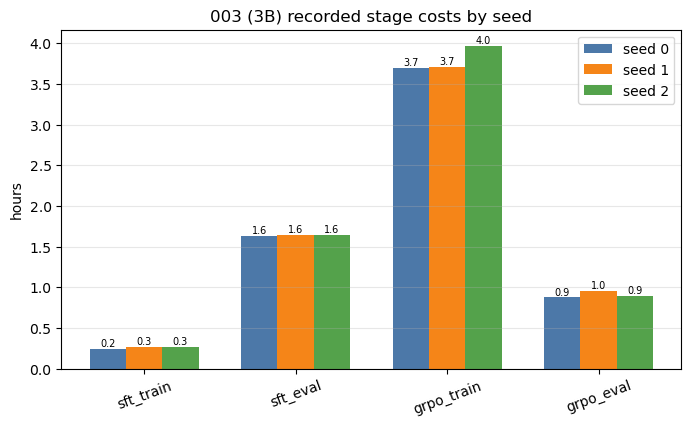

In [13]:
# compare the recorded stage timings for all three 3B seeds
stages = ["sft_train", "sft_eval", "grpo_train", "grpo_eval"]
fig, ax = plt.subplots(figsize=(8, 4.4))
xpos = np.arange(len(stages))
width = 0.24
for index, (seed, data) in enumerate(D3S.items()):
    hours = [data["man"]["timings_sec"].get(stage, 0) / 3600 for stage in stages]
    bars = ax.bar(xpos + (index - 1) * width, hours, width, color=COLORS[seed], label=f"seed {seed}")
    for bar, value in zip(bars, hours):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.03, f"{value:.1f}", ha="center", fontsize=7)
ax.set_xticks(xpos)
ax.set_xticklabels(stages)
ax.set_ylabel("hours")
ax.set_title("003 (3B) recorded stage costs by seed")
ax.legend()
plt.xticks(rotation=20)
ax.grid(alpha=0.3, axis="y")
save(fig, "fig12_stage_cost_3b")
plt.show()

## 6. SFT overfitting check (train vs validation loss)

Train loss is logged every SFT step and validation loss every 50 steps on a held-out
GSM8K slice. The dashed line marks the lowest validation loss. This checks overfitting
to the SFT task and format, not to the MMLU evaluation. GRPO has no matching validation
loss, so its main training checks are the reward, KL and rollout curves above.

saved fig13_sft_train_val_loss


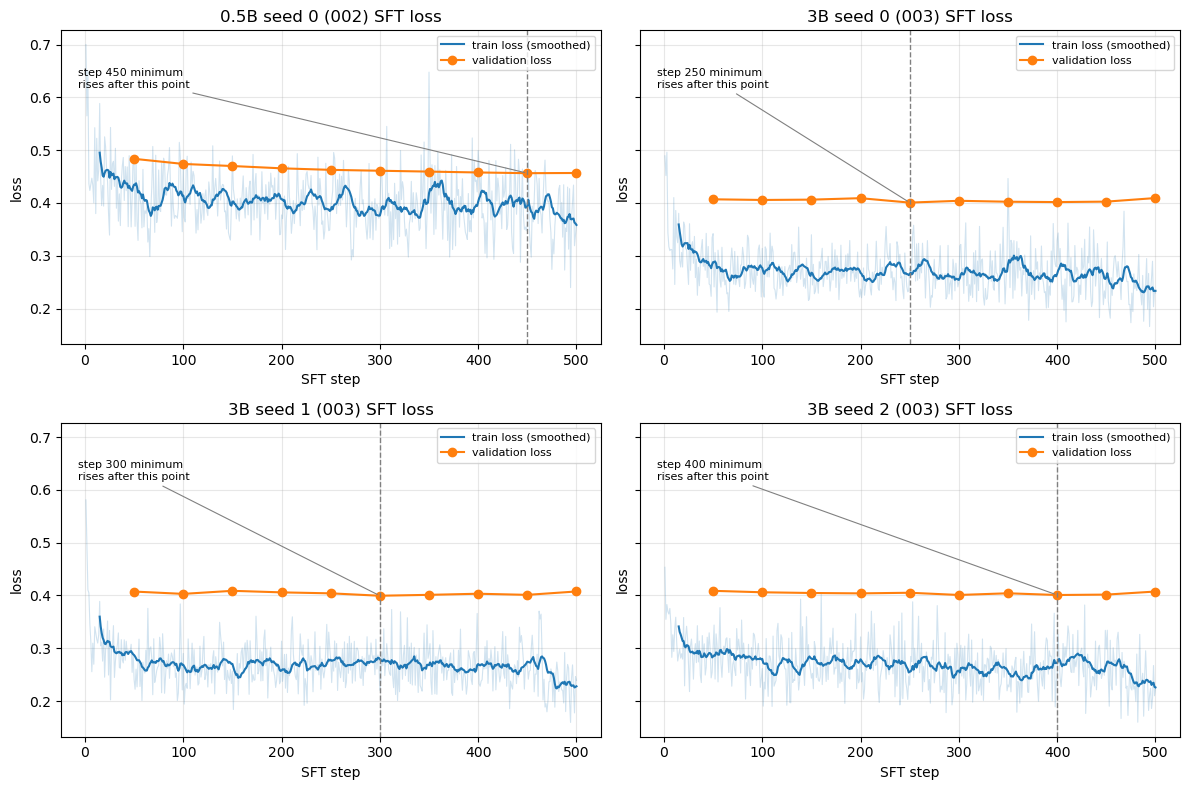

In [14]:
# compare train and held-out GSM8K validation loss for every available run
panels = [(D2, "0.5B seed 0 (002)")] + [(D3S[seed], f"3B seed {seed} (003)") for seed in SEEDS]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, (data, label) in zip(axes.flat, panels):
    train_x, train_loss = series(data["s"], "loss")
    val_x, val_loss = series(data["s"], "eval_loss")
    if len(train_loss):
        ax.plot(train_x, train_loss, color="tab:blue", alpha=0.2, lw=0.8)
        if len(train_loss) >= 15:
            ax.plot(train_x[14:], smooth(train_loss), color="tab:blue", label="train loss (smoothed)")
        else:
            ax.plot(train_x, train_loss, color="tab:blue", label="train loss")
    if len(val_loss):
        ax.plot(val_x, val_loss, "o-", color="tab:orange", label="validation loss")
        minimum = int(np.argmin(val_loss))
        ax.axvline(val_x[minimum], ls="--", c="grey", lw=1)
        note = "rises after this point" if minimum < len(val_loss) - 1 else "minimum is at the end"
        ax.annotate(
            f"step {val_x[minimum]} minimum\n{note}", xy=(val_x[minimum], val_loss[minimum]),
            xytext=(0.03, 0.88), textcoords="axes fraction", ha="left", va="top", fontsize=8,
            arrowprops={"arrowstyle": "-", "color": "grey", "lw": 0.8},
        )
    else:
        ax.text(0.5, 0.5, "no validation loss logged", ha="center", transform=ax.transAxes)
    ax.set_title(f"{label} SFT loss")
    ax.set_xlabel("SFT step")
    ax.set_ylabel("loss")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.3)
fig.tight_layout()
save(fig, "fig13_sft_train_val_loss")
plt.show()

## 7. Metrics tables

Every number is computed from the saved artifacts. The table values are the source for
the plots and the final conclusion. Tier values use the current subject mapping.

In [15]:
# calculate generative and knowledge-probe accuracy by tier
def overall(rows):
    return float(np.mean([row["correct"] for row in rows]))

run_list = [("0.5B", 0, D2)] + [("3B", seed, D3S[seed]) for seed in SEEDS]
rows = []
for scale, seed, data in run_list:
    for condition in COND:
        eval_tiers = data["eval"][condition]["per_tier_acc"]
        probe_tiers = data["lp"][condition]["per_tier_acc"]
        rows.append({
            "scale": scale, "seed": seed, "condition": condition,
            "gen_easy": eval_tiers["easy"], "gen_medium": eval_tiers["medium"],
            "gen_hard": eval_tiers["hard"], "gen_overall": overall(data["preds"][condition]),
            "probe_easy": probe_tiers["easy"], "probe_medium": probe_tiers["medium"],
            "probe_hard": probe_tiers["hard"], "probe_overall": overall(data["lp_preds"][condition]),
        })
acc_tbl = pd.DataFrame(rows).set_index(["scale", "seed", "condition"])
print("accuracy: generative exact-match and logprob knowledge probe")
display(acc_tbl.round(4))

accuracy: generative exact-match and logprob knowledge probe


gen_easy  gen_medium  gen_hard  gen_overall  probe_easy  \
scale seed condition                                                            
0.5B  0    base         0.2093      0.1576    0.1086       0.1714      0.6860   
           sft          0.2537      0.2282    0.1919       0.2325      0.6758   
           grpo         0.6678      0.5107    0.2652       0.5324      0.6849   
3B    0    base         0.6803      0.5320    0.4949       0.5934      0.8532   
           sft          0.6166      0.4762    0.4394       0.5340      0.8521   
           grpo         0.8294      0.6798    0.5202       0.7160      0.8544   
      1    base         0.6803      0.5320    0.4949       0.5934      0.8532   
           sft          0.5870      0.4450    0.4369       0.5096      0.8578   
           grpo         0.8373      0.6814    0.5505       0.7266      0.8612   
      2    base         0.6803      0.5320    0.4949       0.5934      0.8532   
           sft          0.6246      0.5090    0.4773       0.5563      0.8510   
           grpo         0.8498      0.6864    0.5177       0.7272      0.8567   

                      probe_medium  probe_hard  probe_overall  
scale seed condition                                           
0.5B  0    base             0.5172      0.3636         0.5637  
           sft              0.5238      0.3586         0.5600  
           grpo             0.5222      0.3611         0.5642  
3B    0    base             0.7340      0.4798         0.7362  
           sft              0.7323      0.4848         0.7362  
           grpo             0.7373      0.4949         0.7410  
      1    base             0.7340      0.4798         0.7362  
           sft              0.7323      0.5025         0.7426  
           grpo             0.7389      0.4949         0.7447  
      2    base             0.7340      0.4798         0.7362  
           sft              0.7258      0.4747         0.7314  
           grpo             0.7274      0.4773         0.7351

In [16]:
# compare evaluation diagnostics across all three 3B seeds
rows = []
for scale, seed, data in run_list:
    for condition in COND:
        evaluation = data["eval"][condition]
        rows.append({
            "scale": scale, "seed": seed, "condition": condition,
            "format_ok": evaluation["format_compliance"],
            "extract_fail": evaluation["extraction_failure_rate"],
            "mean_len_tokens": evaluation["mean_len"],
        })
diag_tbl = pd.DataFrame(rows).set_index(["scale", "seed", "condition"])
print("evaluation diagnostics")
display(diag_tbl.round(4))

evaluation diagnostics


format_ok  extract_fail  mean_len_tokens
scale seed condition                                          
0.5B  0    base          0.3992        0.4220          84.4183
           sft           0.1773        0.4437         154.4512
           grpo          0.7872        0.0430          63.8992
3B    0    base          0.7489        0.0653         136.0271
           sft           0.7404        0.0701         169.6799
           grpo          0.9644        0.0297          73.7001
      1    base          0.7489        0.0653         136.0271
           sft           0.7017        0.0594         181.2787
           grpo          0.9544        0.0361          81.0626
      2    base          0.7489        0.0653         136.0271
           sft           0.7304        0.0525         173.6040
           grpo          0.9533        0.0281          77.2712

In [17]:
# summarise GRPO rewards on the training prompts and use late-step means
def tail(rows, key, count=20):
    values = [row[key] for row in rows if key in row]
    return float(np.mean(values[-count:])) if values else float("nan")

def head(rows, key, count=20):
    values = [row[key] for row in rows if key in row]
    return float(np.mean(values[:count])) if values else float("nan")

def median(rows, key):
    values = [row[key] for row in rows if key in row]
    return float(np.median(values)) if values else float("nan")

rows = []
for scale, seed, data in run_list:
    trainlog = data["g"]
    rows.append({
        "scale": scale, "seed": seed,
        "accuracy_reward_start": head(trainlog, "rewards/accuracy_reward/mean"),
        "accuracy_reward_end": tail(trainlog, "rewards/accuracy_reward/mean"),
        "format_reward_end": tail(trainlog, "rewards/format_reward/mean"),
        "clipped_end": tail(trainlog, "completions/clipped_ratio"),
        "completion_length_end": tail(trainlog, "completions/mean_length"),
        "kl_late50": tail(trainlog, "kl", 50),
        "kl_median": median(trainlog, "kl"),
        "zero_std_fraction_late": tail(trainlog, "frac_reward_zero_std", 50),
    })
grpo_tbl = pd.DataFrame(rows).set_index(["scale", "seed"])
print("GRPO training endpoints")
display(grpo_tbl.round(4))

GRPO training endpoints


accuracy_reward_start  accuracy_reward_end  format_reward_end  \
scale seed                                                                  
0.5B  0                    0.1812               0.3625             0.1113   
3B    0                    0.3688               0.6562             0.1850   
      1                    0.5000               0.6312             0.1913   
      2                    0.3562               0.6188             0.1813   

            clipped_end  completion_length_end  kl_late50  kl_median  \
scale seed                                                             
0.5B  0          0.0312                84.7250     0.1323     0.0207   
3B    0          0.0188                90.9500     0.0221     0.0138   
      1          0.0062                88.3625     0.0215     0.0134   
      2          0.0062                93.1062     0.0185     0.0098   

            zero_std_fraction_late  
scale seed                          
0.5B  0                       0.00  
3B    0                       0.32  
      1                       0.50  
      2                       0.34

In [18]:
# calculate paired GRPO gains, intervals, McNemar tests and discordant counts
rows = []
for scale, seed, data in run_list:
    sft_rows, grpo_rows = align_pred_rows(data["preds"]["sft"], data["preds"]["grpo"])
    for tier in TIERS + ["overall"]:
        paired = [
            (a["correct"], b["correct"]) for a, b in zip(sft_rows, grpo_rows)
            if tier == "overall" or a["tier"] == tier
        ]
        sft = [a for a, _ in paired]
        grpo = [b for _, b in paired]
        delta, low, high = paired_delta_ci(sft, grpo, seed=500 + seed)
        sft_only = sum(a and not b for a, b in paired)
        grpo_only = sum(not a and b for a, b in paired)
        rows.append({
            "scale": scale, "seed": seed, "tier": tier,
            "delta": delta, "ci_low": low, "ci_high": high,
            "mcnemar_p": mcnemar_exact(sft_only, grpo_only),
            "sft_only": sft_only, "grpo_only": grpo_only,
        })
delta_tbl = pd.DataFrame(rows).set_index(["scale", "seed", "tier"])
print("GRPO accuracy gain over SFT")
display(delta_tbl.round(4))

GRPO accuracy gain over SFT


delta  ci_low  ci_high  mcnemar_p  sft_only  grpo_only
scale seed tier                                                            
0.5B  0    easy     0.4141  0.3766   0.4505     0.0000        32        396
           medium   0.2824  0.2348   0.3284     0.0000        40        212
           hard     0.0732  0.0202   0.1263     0.0087        43         72
           overall  0.2999  0.2744   0.3254     0.0000       115        680
3B    0    easy     0.2127  0.1809   0.2457     0.0000        34        221
           medium   0.2036  0.1609   0.2463     0.0000        40        164
           hard     0.0808  0.0354   0.1288     0.0011        30         62
           overall  0.1821  0.1587   0.2059     0.0000       104        447
      1    easy     0.2503  0.2162   0.2856     0.0000        37        257
           medium   0.2365  0.1938   0.2808     0.0000        39        183
           hard     0.1136  0.0657   0.1641     0.0000        31         76
           overall  0.2171  0.1932   0.2410     0.0000       107        516
      2    easy     0.2253  0.1911   0.2582     0.0000        35        233
           medium   0.1773  0.1363   0.2200     0.0000        40        148
           hard     0.0404 -0.0101   0.0909     0.1371        43         59
           overall  0.1709  0.1476   0.1943     0.0000       118        440

In [19]:
# keep the recorded wall-clock time for every available run
rows = []
for scale, seed, data in run_list:
    timings = data["man"]["timings_sec"]
    row = {"scale": scale, "seed": seed}
    row.update({key: value / 3600 for key, value in timings.items()})
    row["total_hours"] = sum(timings.values()) / 3600
    rows.append(row)
compute_tbl = pd.DataFrame(rows).set_index(["scale", "seed"])
print("compute hours per stage")
display(compute_tbl.round(2))

compute hours per stage


base_eval  base_logprob_eval  sft_train  sft_eval  \
scale seed                                                      
0.5B  0          0.91               0.03       1.27      1.34   
3B    0           NaN                NaN       0.24      1.63   
      1           NaN                NaN       0.26      1.65   
      2           NaN                NaN       0.26      1.64   

            sft_logprob_eval  grpo_train  grpo_eval  grpo_logprob_eval  \
scale seed                                                               
0.5B  0                 0.04        5.47       0.74               0.04   
3B    0                 0.01        3.70       0.87               0.01   
      1                 0.01        3.71       0.96               0.01   
      2                 0.01        3.97       0.89               0.01   

            total_hours  
scale seed               
0.5B  0            9.84  
3B    0            6.47  
      1            6.60  
      2            6.78

In [20]:
# keep per-subject accuracy and GRPO gains for both scales
def subject_rows(data, scale, seed):
    rows = []
    for subject in data["eval"]["grpo"]["per_subject_acc"]:
        rows.append({
            "scale": scale, "seed": seed, "subject": subject, "tier": tier_of(subject),
            "base": data["eval"]["base"]["per_subject_acc"][subject],
            "sft": data["eval"]["sft"]["per_subject_acc"][subject],
            "grpo": data["eval"]["grpo"]["per_subject_acc"][subject],
            "grpo_minus_sft": data["eval"]["grpo"]["per_subject_acc"][subject] - data["eval"]["sft"]["per_subject_acc"][subject],
        })
    return rows

rows = subject_rows(D2, "0.5B", 0)
for seed in SEEDS:
    rows.extend(subject_rows(D3S[seed], "3B", seed))
subject_tbl = pd.DataFrame(rows).set_index(["scale", "seed", "subject"])
print("per-subject accuracy and GRPO gain over SFT")
display(subject_tbl.round(4))

per-subject accuracy and GRPO gain over SFT


tier    base     sft    grpo  \
scale seed subject                                                   
0.5B  0    business_ethics          medium  0.1400  0.2500  0.4600   
           formal_logic               hard  0.1667  0.1825  0.3333   
           high_school_geography    medium  0.1364  0.2374  0.5808   
           high_school_mathematics    hard  0.0815  0.1963  0.2333   
           high_school_psychology     easy  0.2018  0.2477  0.6220   
           marketing                  easy  0.1966  0.2436  0.7521   
           philosophy               medium  0.1768  0.2154  0.4823   
           us_foreign_policy          easy  0.2800  0.3100  0.7200   
3B    0    business_ethics          medium  0.5900  0.4700  0.7200   
           formal_logic               hard  0.4444  0.3889  0.4683   
           high_school_geography    medium  0.5303  0.5505  0.6869   
           high_school_mathematics    hard  0.5185  0.4630  0.5444   
           high_school_psychology     easy  0.6771  0.6752  0.8404   
           marketing                  easy  0.7094  0.5128  0.8205   
           philosophy               medium  0.5145  0.4309  0.6624   
           us_foreign_policy          easy  0.6300  0.5400  0.7900   
      1    business_ethics          medium  0.5900  0.4100  0.7200   
           formal_logic               hard  0.4444  0.3413  0.4603   
           high_school_geography    medium  0.5303  0.5253  0.6970   
           high_school_mathematics    hard  0.5185  0.4815  0.5926   
           high_school_psychology     easy  0.6771  0.6514  0.8404   
           marketing                  easy  0.7094  0.4615  0.8462   
           philosophy               medium  0.5145  0.4051  0.6592   
           us_foreign_policy          easy  0.6300  0.5300  0.8000   
      2    business_ethics          medium  0.5900  0.3900  0.7500   
           formal_logic               hard  0.4444  0.3810  0.4524   
           high_school_geography    medium  0.5303  0.6010  0.7121   
           high_school_mathematics    hard  0.5185  0.5222  0.5481   
           high_school_psychology     easy  0.6771  0.7083  0.8440   
           marketing                  easy  0.7094  0.4615  0.8675   
           philosophy               medium  0.5145  0.4887  0.6495   
           us_foreign_policy          easy  0.6300  0.5500  0.8400   

                                    grpo_minus_sft  
scale seed subject                                  
0.5B  0    business_ethics                  0.2100  
           formal_logic                     0.1508  
           high_school_geography            0.3434  
           high_school_mathematics          0.0370  
           high_school_psychology           0.3743  
           marketing                        0.5085  
           philosophy                       0.2669  
           us_foreign_policy                0.4100  
3B    0    business_ethics                  0.2500  
           formal_logic                     0.0794  
           high_school_geography            0.1364  
           high_school_mathematics          0.0815  
           high_school_psychology           0.1651  
           marketing                        0.3077  
           philosophy                       0.2315  
           us_foreign_policy                0.2500  
      1    business_ethics                  0.3100  
           formal_logic                     0.1190  
           high_school_geography            0.1717  
           high_school_mathematics          0.1111  
           high_school_psychology           0.1890  
           marketing                        0.3846  
           philosophy                       0.2540  
           us_foreign_policy                0.2700  
      2    business_ethics                  0.3600  
           formal_logic                     0.0714  
           high_school_geography            0.1111  
           high_school_mathematics          0.0259  
           high_school_psychology           0.1358  
           mar

## 8. Accuracy overview

The top row is generative exact-match and the bottom row is the logprob knowledge
probe. The 3B bars show the three-seed mean and full seed range. The 0.5B panel is
the original experiment 002 comparison, so it has one seed.

saved fig14_accuracy_overview


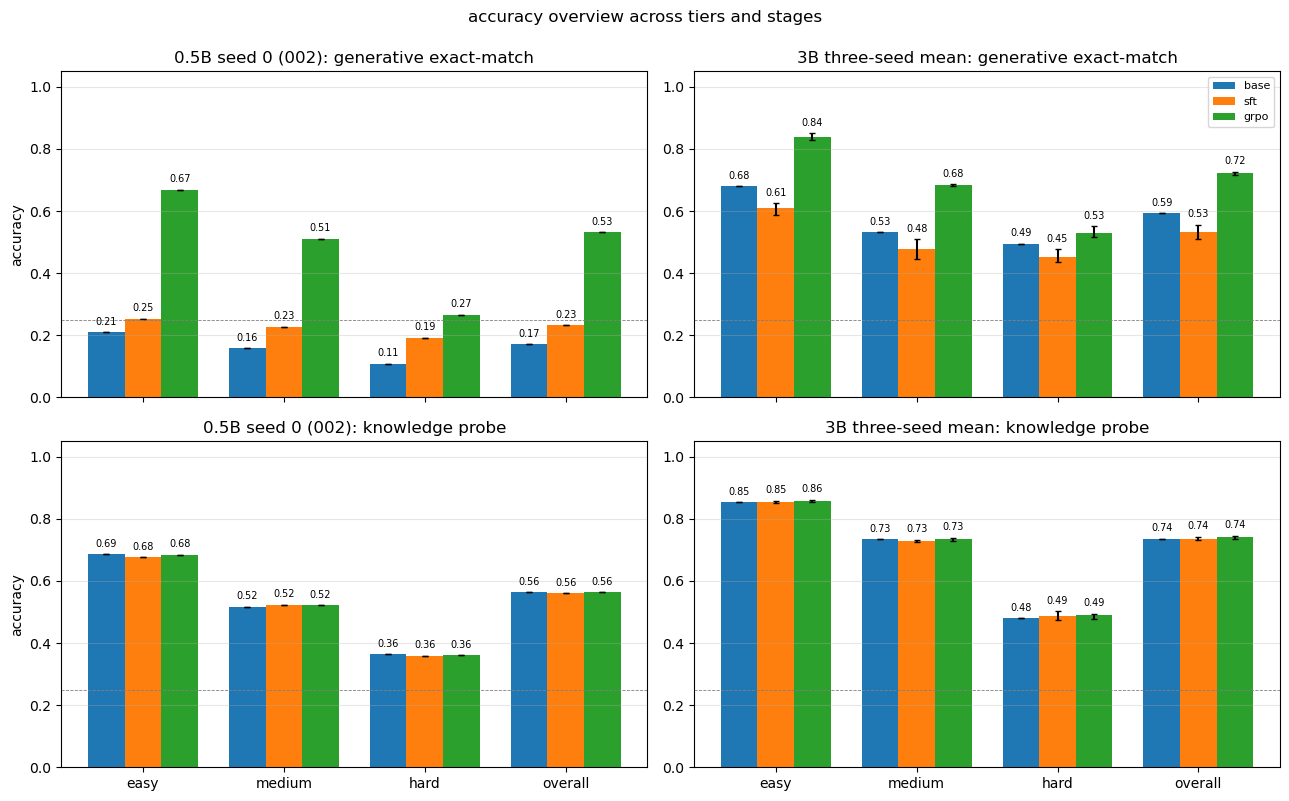

In [21]:
# show the 3B three-seed mean and range in the full accuracy overview
def accuracy_values(data, condition, probe=False):
    summary = data["lp"][condition] if probe else data["eval"][condition]
    rows = data["lp_preds"][condition] if probe else data["preds"][condition]
    return [summary["per_tier_acc"][tier] for tier in TIERS] + [overall(rows)]

groups = TIERS + ["overall"]
xpos = np.arange(len(groups))
width = 0.26
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for row, (title, probe) in enumerate((("generative exact-match", False), ("knowledge probe", True))):
    for col, (datasets, scale) in enumerate((((D2,), "0.5B seed 0 (002)"), (tuple(D3S.values()), "3B three-seed mean"))):
        ax = axes[row][col]
        for index, condition in enumerate(COND):
            seed_values = np.array([accuracy_values(data, condition, probe) for data in datasets])
            values = seed_values.mean(axis=0)
            errors = np.vstack([
                np.maximum(values - seed_values.min(axis=0), 0),
                np.maximum(seed_values.max(axis=0) - values, 0),
            ])
            bars = ax.bar(xpos + (index - 1) * width, values, width, yerr=errors, capsize=2, label=condition)
            labels = [f"{value:.2f}" for value in values]
            ax.bar_label(bars, labels=labels, padding=4, fontsize=7)
        ax.axhline(0.25, color="grey", lw=0.6, ls="--")
        ax.set_ylim(0, 1.05)
        ax.set_xticks(xpos)
        ax.set_xticklabels(groups)
        ax.set_title(f"{scale}: {title}")
        ax.grid(alpha=0.3, axis="y")
        if row == 0 and col == 1:
            ax.legend(loc="upper right", fontsize=8)
axes[0][0].set_ylabel("accuracy")
axes[1][0].set_ylabel("accuracy")
fig.suptitle("accuracy overview across tiers and stages", y=0.995)
fig.tight_layout()
save(fig, "fig14_accuracy_overview")
plt.show()

## 9. Evaluation diagnostics

Format compliance, extraction failure and mean response length are shown by condition.
The 3B bars use the three-seed mean and full seed range.

saved fig15_eval_diagnostics


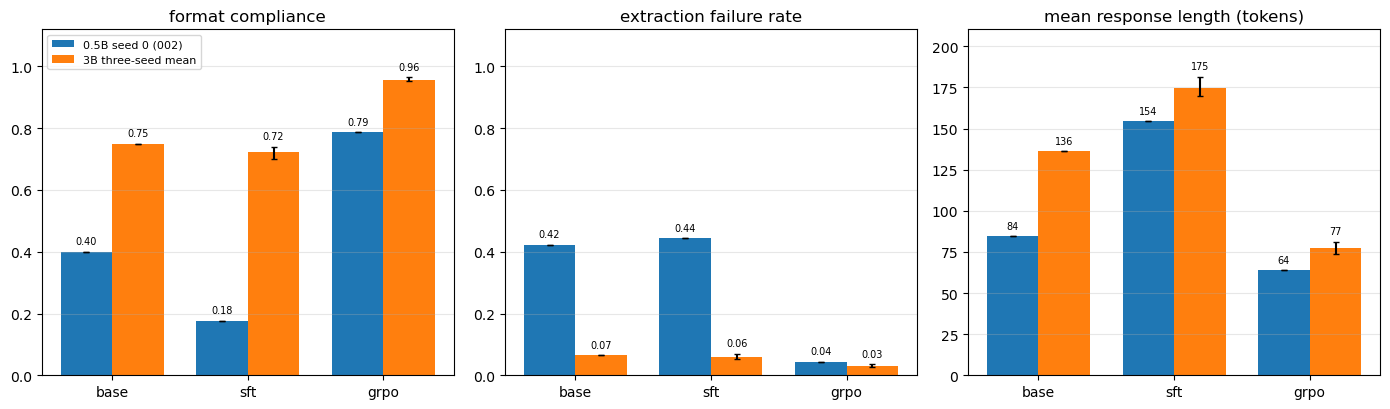

In [22]:
# show the 3B three-seed range in each evaluation diagnostic
metrics = [
    ("format_compliance", "format compliance"),
    ("extraction_failure_rate", "extraction failure rate"),
    ("mean_len", "mean response length (tokens)"),
]
xpos = np.arange(len(COND))
width = 0.38
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (key, title) in zip(axes, metrics):
    for index, (datasets, scale) in enumerate((((D2,), "0.5B seed 0 (002)"), (tuple(D3S.values()), "3B three-seed mean"))):
        seed_values = np.array([[data["eval"][condition][key] for condition in COND] for data in datasets])
        values = seed_values.mean(axis=0)
        errors = np.vstack([
            np.maximum(values - seed_values.min(axis=0), 0),
            np.maximum(seed_values.max(axis=0) - values, 0),
        ])
        bars = ax.bar(xpos + (index - 0.5) * width, values, width, yerr=errors, capsize=2, label=scale)
        labels = [f"{value:.0f}" if key == "mean_len" else f"{value:.2f}" for value in values]
        ax.bar_label(bars, labels=labels, padding=4, fontsize=7)
    ax.set_xticks(xpos)
    ax.set_xticklabels(COND)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    if key != "mean_len":
        ax.set_ylim(0, 1.12)
    else:
        ax.margins(y=0.16)
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "fig15_eval_diagnostics")
plt.show()

## 10. Three-seed stability

The third seed was added to check whether the original 3B result depended on one lucky
run. These plots keep the three endpoints separate and show the max-minus-min range.

saved fig16_seed_stability_3b


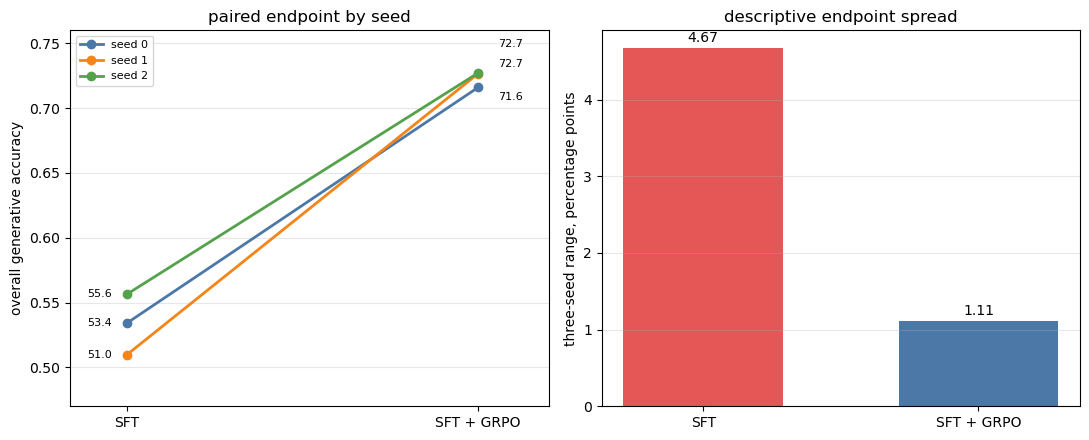

,sft,grpo,grpo_gain_points
seed,,,
0,0.5340,0.7160,18.2059
1,0.5096,0.7266,21.7091
2,0.5563,0.7272,17.0913


mean GRPO gain: 19.00 points
final GRPO range: 1.11 points


In [23]:
# compare paired endpoints and the descriptive seed spread
seed_rows = []
for seed, data in D3S.items():
    sft_accuracy = overall(data["preds"]["sft"])
    grpo_accuracy = overall(data["preds"]["grpo"])
    seed_rows.append({
        "seed": seed,
        "sft": sft_accuracy,
        "grpo": grpo_accuracy,
        "grpo_gain_points": 100 * (grpo_accuracy - sft_accuracy),
    })
seed_summary = pd.DataFrame(seed_rows).set_index("seed")
spread_sft = 100 * (seed_summary["sft"].max() - seed_summary["sft"].min())
spread_grpo = 100 * (seed_summary["grpo"].max() - seed_summary["grpo"].min())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for seed, row in seed_summary.iterrows():
    values = [row["sft"], row["grpo"]]
    axes[0].plot([0, 1], values, "o-", lw=2, color=COLORS[seed], label=f"seed {seed}")
    axes[0].text(-0.04, values[0], f"{100 * values[0]:.1f}", ha="right", va="center", fontsize=8)
    endpoint_offset = {0: -7, 1: 7, 2: 21}[seed]
    axes[0].annotate(
        f"{100 * values[1]:.1f}", xy=(1, values[1]), xytext=(14, endpoint_offset),
        textcoords="offset points", ha="left", va="center", fontsize=8,
    )
axes[0].set_xlim(-0.16, 1.2)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["SFT", "SFT + GRPO"])
axes[0].set_ylabel("overall generative accuracy")
axes[0].set_ylim(0.47, 0.76)
axes[0].set_title("paired endpoint by seed")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, axis="y")

bars = axes[1].bar(["SFT", "SFT + GRPO"], [spread_sft, spread_grpo], color=["#E45756", "#4C78A8"], width=0.58)
for bar, value in zip(bars, [spread_sft, spread_grpo]):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.08, f"{value:.2f}", ha="center")
axes[1].set_ylabel("three-seed range, percentage points")
axes[1].set_title("descriptive endpoint spread")
axes[1].grid(alpha=0.3, axis="y")
fig.tight_layout()
save(fig, "fig16_seed_stability_3b")
plt.show()

display(seed_summary.round(4))
print(f"mean GRPO gain: {seed_summary['grpo_gain_points'].mean():.2f} points")
print(f"final GRPO range: {spread_grpo:.2f} points")

saved fig17_subject_delta_matrix_3b


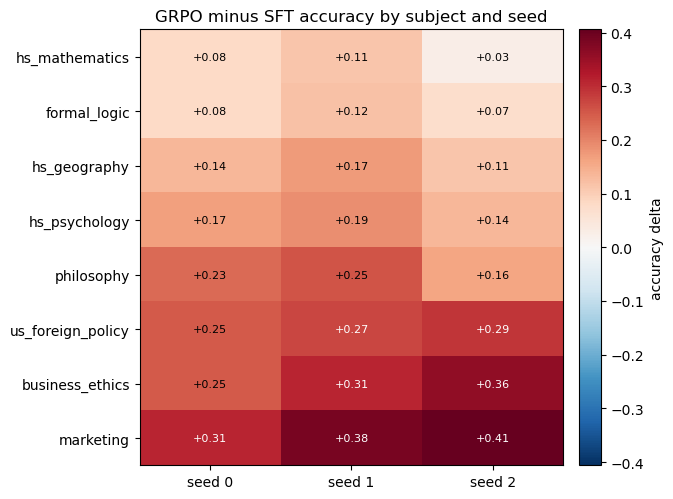

In [24]:
# show subject-level agreement without averaging away seed differences
subject_matrix_values = np.array([
    [D3S[seed]["eval"]["grpo"]["per_subject_acc"][subject] - D3S[seed]["eval"]["sft"]["per_subject_acc"][subject] for seed in SEEDS]
    for subject in subjects
])
order = np.argsort(subject_matrix_values.mean(axis=1))
ordered = subject_matrix_values[order]
labels = [subjects[index].replace("high_school_", "hs_") for index in order]
limit = max(abs(ordered.min()), abs(ordered.max()))

fig, ax = plt.subplots(figsize=(6.8, 5.1))
image = ax.imshow(ordered, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
for row_index in range(ordered.shape[0]):
    for col_index in range(ordered.shape[1]):
        color = heatmap_text_color(image, ordered[row_index, col_index])
        ax.text(col_index, row_index, f"{ordered[row_index, col_index]:+.2f}", ha="center", va="center", fontsize=8, color=color)
ax.set_xticks(range(len(SEEDS)))
ax.set_xticklabels([f"seed {seed}" for seed in SEEDS])
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("GRPO minus SFT accuracy by subject and seed")
colorbar = fig.colorbar(image, ax=ax, pad=0.03)
colorbar.set_label("accuracy delta")
fig.tight_layout()
save(fig, "fig17_subject_delta_matrix_3b")
plt.show()

## Cross-referenced conclusion

The third seed confirms the main 3B result. GRPO improves overall accuracy by
18.2, 21.7 and 17.1 percentage points. Final GRPO accuracy is 71.6%, 72.7% and
72.7%, so the three-seed range is only 1.1 points even though the SFT endpoints
have a wider 4.7-point range. Every tier has a positive point estimate in every
seed, but the hard-tier gain is smaller and seed 2's 95% interval crosses zero.

This makes the 3B improvement look repeatable rather than caused by one lucky seed.
The 0.5B panels here still use experiment 002 as the original RQ2 comparison. The
current A100 cross-scale analysis is kept in the later 006 and 013 analysis notebooks.